# CNN-LSTM
原Notebook保留不动。本副本接入已合并的数据，兼容quant的Python3.12，首次自动训练并回测。
数据2022-01-04至2026-09-11；回测2024-01-02至2026-08-14。


In [1]:
INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    get_ipython().run_line_magic("pip", "install pyqlib==0.9.7 tushare==1.4.24 torch==2.6.0 numpy==1.26.4 pandas==2.2.3 scikit-learn==1.6.1 pyarrow==19.0.1 matplotlib==3.10.1 mlflow==2.22.0 nbformat nbclient ipykernel")
    print("please reset core")


过滤项集中在 `filters`；关闭该字典的 enabled 即可恢复不加过滤的选股。增强策略仅保留排序权重和市场宽度参数。
直接修改 `enhanced.momentum_weight`（0～1），模型占比自动取 1 − 动量占比；用 `breadth_timing` 开关控制宽度择时。修改后执行配置单元和最后的收益图单元，覆盖更新当前图表。

In [2]:
import sys, os, re, json, math, random, hashlib, copy, logging
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import qlib
from qlib.strategy.base import BaseStrategy
from qlib.backtest.decision import Order, TradeDecisionWO
from qlib.backtest.exchange import Exchange
from qlib.backtest import backtest
from IPython.display import display, Markdown
from matplotlib.ticker import PercentFormatter
from matplotlib.dates import DateFormatter

CONFIG = {
    "data": {"start_date": "2022-01-01", "end_date": "2026-09-12",
             "raw_dir": "data/raw", "processed_dir": "data/processed", "qlib_dir": "data/qlib",
             "benchmark": "399101.SZ", "calls_per_minute": 40, "retries": 3, "timeout": 20,
             "workers": 8, "refresh_days": 5, "financial_lookback_years": 2, "announcement_lag": 0,
             "min_listing_days": 375, "candidate_count": 50, "missing_sequence": "drop"},
    "model": {"feature_schema": "financial18_v1", "seed": 42, "device": "cpu", "threads": 2, "epochs": 30, "batch_size": 16,
              "learning_rate": 1e-4, "early_stopping_patience": 5, "gradient_clip": 1.0,
              "conv_channels": [64, 128], "hidden_size": 128, "lstm_layers": 2,
              "conv_dropout": 0.3, "lstm_dropout": 0.3, "dense_dropout": 0.4,
              "impute": "median", "winsor_quantiles": [0.01, 0.99], "standardize": True,
              "lookback_months": 12, "validation_fraction": 0.2, "purge_days": 20, "sample_step": 10},
    "backtest": {"start_date": "2024-01-02", "end_date": "2026-08-14", "rebalance_step": 10,
                 "topk": 10, "initial_cash": 1000000.0, "buy_commission": 0.0003,
                 "sell_commission": 0.0003, "stamp_tax": 0.001, "min_commission": 5.0,
                 "trade_unit": 100, "output_dir": "outputs/filtered_model", "risk_free_rate": 0.0},
    # Optional filters: disable all with enabled=False; disable individual rules below.
    "filters": {"enabled": True, "exclude_st": True, "exclude_delisting": True,    #################################################
                "min_price": 1.5, "liquidity_quantile": 0.30},
    "enhanced": {"enabled": True, "output_dir": "outputs/filtered_enhanced_m075_no_breadth",
                 "momentum_weight": 1, "breadth_timing": True,  # Model weight = 1 - momentum_weight; False disables timing.========================================
                 "breadth_threshold": 0.50,
                 "risk_exit_confirmation_days": 3},
    "run": {"download": False, "train_backtest": False, "refresh_all": False}
}

PROJECT_ROOT = Path(os.environ.get("QLIB_PROJECT_ROOT", Path.cwd())).resolve()
if not (PROJECT_ROOT / "data/processed/panel.parquet").exists():
    candidates = [Path.cwd() / "CNN_LSTM_Project", *Path.cwd().parents]
    PROJECT_ROOT = next((p.resolve() for p in candidates if (p / "data/processed/panel.parquet").exists()), PROJECT_ROOT)
if not (PROJECT_ROOT / "data/processed/panel.parquet").exists():
    raise FileNotFoundError("请从完整项目文件夹启动，或使用运行完整项目.cmd。")
for key in ("raw_dir", "processed_dir", "qlib_dir"):
    CONFIG["data"][key] = str(PROJECT_ROOT / CONFIG["data"][key])
CONFIG["backtest"]["output_dir"] = str(PROJECT_ROOT / CONFIG["backtest"]["output_dir"])
CONFIG["enhanced"]["output_dir"] = str(PROJECT_ROOT / CONFIG["enhanced"]["output_dir"])



assert sys.version_info[:2] in ((3, 10), (3, 11), (3, 12)), "请选择 Python 3.10/3.11/3.12 或 quant 内核"
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")
LOG = logging.getLogger("microcap")
pd.set_option("future.no_silent_downcasting", True)

def validate_config(cfg):
    d, m, b = cfg["data"], cfg["model"], cfg["backtest"]
    assert pd.Timestamp(d["start_date"]) <= pd.Timestamp(b["start_date"]) <= pd.Timestamp(b["end_date"]) < pd.Timestamp(d["end_date"])
    assert d["missing_sequence"] in ("drop", "ffill")
    assert d["announcement_lag"] >= 0 and d["candidate_count"] == 50 and d["min_listing_days"] >= 375
    assert m["sample_step"] == b["rebalance_step"] == 10 and m["purge_days"] >= 20
    assert 0 < m["validation_fraction"] < 1 and b["topk"] == 10 and b["initial_cash"] > 0
    assert m["epochs"] > 0 and m["batch_size"] > 0
    assert m["impute"] in ("median", "raise")
    filters = cfg.get("filters", {})
    assert filters.get("min_price", 0) >= 0 and 0 <= filters.get("liquidity_quantile", 0) < 1
    e = cfg.get("enhanced", {})
    if e.get("enabled", False):
        momentum = e.get("momentum_weight", 1 - e.get("model_weight", 0.75))
        assert 0 <= momentum <= 1, "momentum_weight must be between 0 and 1"
        e["momentum_weight"], e["model_weight"] = momentum, 1 - momentum
        assert 0 <= e["breadth_threshold"] <= 1
        assert e["risk_exit_confirmation_days"] >= 1
        assert isinstance(e.get("breadth_timing", True), bool)
    assert 0 <= m["winsor_quantiles"][0] < m["winsor_quantiles"][1] <= 1

def write_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str, allow_nan=False), encoding="utf-8")

def set_seed(seed=42, threads=2):
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.set_num_threads(threads)
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False

validate_config(CONFIG)
set_seed(CONFIG["model"]["seed"], CONFIG["model"]["threads"])
print("Python", sys.version.split()[0], "| Qlib", qlib.__version__, "| Torch", torch.__version__)

Python 3.12.15 | Qlib 0.9.7 | Torch 2.6.0+cpu


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


## 特征与标签
18 个特征 × 5 个采样时点，模型输入为 5×18（展开为90列）。新增经营现金流净额／总资产、资产负债率、营业收入同比增长率，直接参与 CNN-LSTM 训练，没有独立开关、分数或组合权重。原净利润同比仍保留，新增同比指营收增长。

经营现金流使用财报年初至报告期末的累计值，除以同一报告期末的总资产，不是TTM或单季度现金流。仅使用合并报表，等现金流和资产两份数据的公告日期均到达后才生效；资产非正数或缺失时保留缺失值。资产负债率、营收同比除以100转换为比例。新增字段定义来自 [财务指标](https://tushare.pro/document/2?doc_id=79)、[现金流量表](https://tushare.pro/document/2?doc_id=44)、[资产负债表](https://tushare.pro/document/2?doc_id=36)。


In [3]:
# 使用处理数据仍需要以下日历、股票池与过滤规则；均原样保留。
class TradingCalendar:
    def __init__(self, dates):
        self.dates = pd.DatetimeIndex(pd.to_datetime(dates)).normalize().unique().sort_values()
        self.positions = {d: i for i, d in enumerate(self.dates)}

    def shift(self, date, offset):
        pos = self.positions[pd.Timestamp(date)] + offset
        if pos < 0 or pos >= len(self.dates):
            raise IndexError("Trading calendar has insufficient history or future coverage")
        return self.dates[pos]

    def between(self, start, end):
        return self.dates[(self.dates >= pd.Timestamp(start)) & (self.dates <= pd.Timestamp(end))]

    def schedule(self, start, end, step=10):
        return self.between(start, end)[::step]

def historical_universe(panel, date, count=50, min_listing_days=375):
    day = pd.Timestamp(date)
    rows = panel.xs(day, level="datetime").copy()
    code = rows.ts_code
    main_a = ((code.str.endswith(".SZ") & code.str.startswith(("000", "001", "002", "003", "300", "301"))) |
              (code.str.endswith(".SH") & code.str.startswith(("600", "601", "603", "605"))))
    valid = main_a & ~code.str.startswith(("688", "689"))
    valid &= (day - rows.list_date).dt.days.ge(min_listing_days)
    valid &= rows.delist_date.isna() | rows.delist_date.gt(day)
    valid &= ~rows.suspended.fillna(True).astype(bool)
    valid &= rows[["open", "high", "low", "close", "vol", "total_mv"]].gt(0).all(axis=1)
    valid &= np.isfinite(rows[["open", "high", "low", "close", "vol", "total_mv"]]).all(axis=1)
    return rows.loc[valid].sort_values(["total_mv", "ts_code"], kind="stable").head(count).index.tolist()

def filter_candidates(rows, date, filters):
    """Use only the status, unadjusted price and amount visible on the signal date."""
    if not filters.get("enabled", False) or rows.empty:
        return rows
    mask = pd.Series(True, index=rows.index)
    if filters.get("exclude_delisting", False):
        mask &= rows.delist_date.isna() | rows.delist_date.gt(pd.Timestamp(date))
    for option, field in (("exclude_st", "is_st"), ("exclude_delisting", "is_delisting")):
        if filters.get(option, False):
            if field not in rows or rows[field].isna().any():
                raise ValueError(f"Missing historical namechange coverage on {date}; enable download first")
            mask &= ~rows[field].astype(bool)
    if filters.get("min_price", 0) > 0:
        mask &= rows.close.ge(filters["min_price"])
    quantile = filters.get("liquidity_quantile", 0)
    if quantile > 0:
        mask &= rows.amount.ge(rows.amount.quantile(quantile))
    return rows.loc[mask]


FEATURES = ["pe_ttm", "pb", "ps_ttm", "log_total_mv", "turnover_rate", "roa", "roe",
            "netprofit_yoy_ratio", "grossprofit_margin_ratio", "netprofit_margin_ratio",
            "ocf_to_assets", "debt_to_assets_ratio", "or_yoy_ratio",
            "momentum_5", "momentum_10", "momentum_20", "volatility_20", "volume_ratio_5"]
OFFSETS = [84, 63, 42, 21, 0]
COLUMNS = [f"lag{lag:02d}_{feature}" for lag in OFFSETS for feature in FEATURES]


def sequences(panel, calendar, dates, universes, missing="drop"):
    if missing not in ("drop", "ffill"):
        raise ValueError("Unsupported missing sequence policy")
    features = panel[FEATURES]
    if missing == "ffill":
        features = features.groupby(level="instrument").ffill()
    records, index = [], []
    for date in dates:
        date = pd.Timestamp(date)
        try:
            times = [calendar.shift(date, -lag) for lag in OFFSETS]
        except IndexError:
            continue
        for code in universes.get(date, []):
            key = pd.MultiIndex.from_tuples([(t, code) for t in times], names=["datetime", "instrument"])
            seq = features.reindex(key).to_numpy(dtype=float)
            # A complete sequence needs all five historical periods. Individual missing
            # features are handled later using statistics fitted on the training split only.
            # ffill never manufactures a zero sequence or fills backward from a later date.
            if np.isnan(seq).all(axis=1).any():
                continue
            records.append(seq.reshape(len(COLUMNS)))
            index.append((date, code))
    idx = pd.MultiIndex.from_tuples(index, names=["datetime", "instrument"])
    return pd.DataFrame(records, index=idx, columns=COLUMNS).sort_index()


def build_labels(panel, benchmark, calendar, sample_index, asof=None):
    """Labels are a separate artifact; all endpoint dates are retained for auditing."""
    records = []
    cutoff = pd.Timestamp(asof) if asof is not None else calendar.dates[-1]
    for date, code in sample_index:
        try:
            entry, end = calendar.shift(date, 1), calendar.shift(date, 20)
        except IndexError:
            continue
        if end > cutoff:
            continue
        s0, s1 = panel.loc[(entry, code), "adj_open"], panel.loc[(end, code), "adj_close"]
        b0, b1 = benchmark.loc[entry, "open"], benchmark.loc[end, "close"]
        if not np.isfinite([s0, s1, b0, b1]).all() or min(s0, s1, b0, b1) <= 0:
            continue
        sr, br = s1 / s0 - 1, b1 / b0 - 1
        records.append(dict(datetime=date, instrument=code, label=float(sr > br),
                            excess_return=sr - br, label_start=entry, label_end=end))
    columns = ["datetime", "instrument", "label", "excess_return", "label_start", "label_end"]
    return pd.DataFrame(records, columns=columns).set_index(["datetime", "instrument"]).sort_index()


## 已合并的本地数据
原始缓存与补齐缓存统一在 `data/raw`，18特征面板在 `data/processed`，Qlib数据在 `data/qlib`。本Notebook直接使用项目内已整理的数据，不依赖下载或恢复脚本。


In [4]:
def to_qlib(code):
    if not re.fullmatch(r"\d{6}\.(SH|SZ)", code):
        raise ValueError(f"Unsupported Shanghai/Shenzhen code: {code}")
    number, exchange = code.split(".")
    return exchange + number


def dump_bin(panel, benchmark, calendar, output, benchmark_code="SZ399101"):
    """Qlib float32 format: starting calendar index followed by daily values.

    Rebuild affected histories atomically, so incremental vendor changes cannot leave
    stale tails. Raw Parquet remains the recoverable source of truth.
    """
    root = Path(output)
    for sub in ("calendars", "instruments", "features"):
        (root / sub).mkdir(parents=True, exist_ok=True)
    dates = calendar.dates
    (root / "calendars/day.txt").write_text("\n".join(dates.strftime("%Y-%m-%d")) + "\n", encoding="utf-8")
    instruments = []
    for code, g in panel.groupby(level="instrument", sort=True):
        g = g.droplevel("instrument").reindex(dates)
        raw_open = g.open
        suspended = g.suspended.fillna(True) | raw_open.isna() | raw_open.le(0)
        missing_limits = g.up_limit.isna() | g.down_limit.isna()
        factor = g.adj_factor.ffill().bfill().fillna(1.0)
        values = {f: g[f] for f in FEATURES}
        values.update({f: g[f] * factor for f in ("open", "high", "low", "close")})
        values.update(factor=factor, volume=g.vol * 100 / factor,
                      change=g.close / g.pre_close - 1,
                      blocked_buy=(suspended | missing_limits | raw_open.ge(g.up_limit - 0.005)).astype(float),
                      blocked_sell=(suspended | missing_limits | raw_open.le(g.down_limit + 0.005)).astype(float))
        # A missing final liquidation quote cannot justify preserving a delisted holding's NAV.
        delisted = g.delist_date.notna() & (dates >= g.delist_date)
        values["close"] = values["close"].mask(delisted, 1e-8)
        values["blocked_buy"] = values["blocked_buy"].mask(delisted, 1.0)
        values["blocked_sell"] = values["blocked_sell"].mask(delisted, 1.0)
        _write_instrument(root, code, values)
        instruments.append(f"{code}\t{dates[0]:%Y-%m-%d}\t{dates[-1]:%Y-%m-%d}")
    b = benchmark.reindex(dates)
    _write_instrument(root, benchmark_code, {**{f: b[f] for f in ("open", "high", "low", "close")},
        "factor": np.ones(len(dates)), "volume": b.vol * 100, "change": b.close.pct_change(fill_method=None),
        "blocked_buy": np.zeros(len(dates)), "blocked_sell": np.zeros(len(dates))})
    instruments.append(f"{benchmark_code}\t{dates[0]:%Y-%m-%d}\t{dates[-1]:%Y-%m-%d}")
    (root / "instruments/all.txt").write_text("\n".join(instruments) + "\n", encoding="utf-8")


def _write_instrument(root, code, values):
    directory = root / "features" / code.lower()
    directory.mkdir(parents=True, exist_ok=True)
    for name, array in values.items():
        path = directory / f"{name.lower()}.day.bin"
        temp = path.with_suffix(".tmp")
        np.concatenate([[0.0], np.asarray(array, dtype=float)]).astype("<f4").tofile(temp)
        temp.replace(path)


def initialize_qlib(path):
    qlib.init(
        provider_uri=str(Path(path).resolve()), region="cn", kernels=1,
        expression_cache=None, dataset_cache=None, logging_level=logging.WARNING,
    )


## 训练集预处理
中位数填补、缩尾与标准化只在训练集拟合，验证和预测只做转换。

In [5]:
def tensor_values(frame):
    if list(frame.columns) != COLUMNS:
        raise ValueError(f"{len(COLUMNS)} columns must match oldest-to-newest time and fixed feature order")
    return frame.to_numpy(dtype=np.float64).reshape(-1, len(OFFSETS), len(FEATURES))

class TrainPreprocessor:
    def __init__(self, config):
        self.config = copy.deepcopy(config)
        self.fit_calls = 0

    def fit(self, frame):
        x = tensor_values(frame).reshape(-1, len(FEATURES))
        x[~np.isfinite(x)] = np.nan
        if np.isnan(x).all(axis=0).any():
            raise ValueError("Training feature entirely missing")
        self.median = np.nanmedian(x, axis=0)
        self.low, self.high = np.nanquantile(x, self.config["winsor_quantiles"], axis=0)
        self.scaler = StandardScaler(with_mean=self.config["standardize"], with_std=self.config["standardize"])
        self.scaler.fit(self._clean(x))
        self.fit_calls += 1
        self.fit_index = frame.index.tolist()
        return self

    def _clean(self, x):
        x = np.array(x, dtype=float, copy=True)
        x[~np.isfinite(x)] = np.nan
        if np.isnan(x).any() and self.config["impute"] == "raise":
            raise ValueError("Missing feature with impute=raise")
        x = np.where(np.isnan(x), self.median, x)
        return np.clip(x, self.low, self.high)

    def transform(self, frame):
        x = tensor_values(frame)
        return self.scaler.transform(self._clean(x.reshape(-1, len(FEATURES)))).reshape(-1, len(OFFSETS), len(FEATURES)).astype(np.float32)

    def state(self):
        return {"median": self.median.tolist(), "low": self.low.tolist(), "high": self.high.tolist(),
                "mean": self.scaler.mean_.tolist() if self.scaler.mean_ is not None else None,
                "scale": self.scaler.scale_.tolist() if self.scaler.scale_ is not None else None,
                "fit_calls": self.fit_calls, "fit_index": [(str(d), c) for d, c in self.fit_index]}

9. CNN-LSTM 模型
两层 CNN → 平均池化 → 重复 5 次 → 两层 LSTM → 全连接与 Sigmoid。池化后的 LSTM 输入相同，这一现有结构保留；它无法直接读取原始五个时点各自的状态和顺序。
输入通道数跟随特征列表（当前18），模型文件保存特征名与采样顺序；加载时严格核对，拒绝旧15特征模型。

In [6]:
class CNNLSTM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        a, b = cfg["conv_channels"]
        self.conv = nn.Sequential(nn.Conv1d(len(FEATURES), a, 3, padding=1), nn.BatchNorm1d(a), nn.ReLU(),
            nn.Dropout(cfg["conv_dropout"]), nn.Conv1d(a, b, 3, padding=1),
            nn.BatchNorm1d(b), nn.ReLU(), nn.Dropout(cfg["conv_dropout"]))
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.lstm = nn.LSTM(b, cfg["hidden_size"], cfg["lstm_layers"], batch_first=True,
                            dropout=cfg["lstm_dropout"])
        self.head = nn.Sequential(nn.Linear(cfg["hidden_size"], 64), nn.ReLU(),
                                 nn.Dropout(cfg["dense_dropout"]), nn.Linear(64, 1), nn.Sigmoid())

    def forward(self, x):
        if x.ndim != 3 or tuple(x.shape[1:]) != (len(OFFSETS), len(FEATURES)):
            raise ValueError(f"Expected (batch, {len(OFFSETS)}, {len(FEATURES)})")
        features = self.pool(self.conv(x.transpose(1, 2))).squeeze(-1)
        sequence = features.unsqueeze(1).expand(-1, x.shape[1], -1)
        _, (hidden, _) = self.lstm(sequence)
        return self.head(hidden[-1]).squeeze(-1)

class CNNLSTMModel:
    def __init__(self, config):
        self.config = copy.deepcopy(config)
        self.net = None

    def fit(self, features, labels, train_index, valid_index):
        cfg = self.config
        set_seed(cfg["seed"], cfg["threads"])
        xtr, xva = features.loc[train_index], features.loc[valid_index]
        ytr, yva = labels.loc[train_index, ["label"]], labels.loc[valid_index, ["label"]]
        if len(xtr) < 2 or len(xva) < 2: raise ValueError("Insufficient train/validation samples")
        if not np.isfinite(ytr.values).all() or not np.isfinite(yva.values).all():
            raise ValueError("Nonfinite label")
        self.preprocessor = TrainPreprocessor(cfg).fit(xtr)
        xt = torch.from_numpy(self.preprocessor.transform(xtr))
        xv = torch.from_numpy(self.preprocessor.transform(xva))
        yt = torch.tensor(ytr.to_numpy().ravel(), dtype=torch.float32)
        yv = torch.tensor(yva.to_numpy().ravel(), dtype=torch.float32)
        device = torch.device(cfg["device"])
        self.net = CNNLSTM(cfg).to(device)
        loader = DataLoader(TensorDataset(xt, yt), batch_size=cfg["batch_size"], shuffle=True,
                            num_workers=0, generator=torch.Generator().manual_seed(cfg["seed"]))
        optimizer = torch.optim.Adam(self.net.parameters(), lr=cfg["learning_rate"])
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=2, factor=0.5)
        loss_fn = nn.BCELoss()
        best, stale, best_state = float("inf"), 0, None
        self.history = []
        for epoch in range(cfg["epochs"]):
            self.net.train()
            total = 0.0
            for bx, by in loader:
                optimizer.zero_grad()
                loss = loss_fn(self.net(bx.to(device)), by.to(device))
                if not torch.isfinite(loss): raise ValueError("Nonfinite training loss")
                loss.backward()
                nn.utils.clip_grad_norm_(self.net.parameters(), cfg["gradient_clip"])
                optimizer.step()
                total += loss.item() * len(bx)
            self.net.eval()
            with torch.no_grad():
                probabilities = self.net(xv.to(device))
                val_loss = loss_fn(probabilities, yv.to(device)).item()
            if not np.isfinite(val_loss): raise ValueError("Nonfinite validation loss")
            self.history.append({"epoch": epoch+1, "train_loss": total/len(xt), "valid_loss": val_loss})
            scheduler.step(val_loss)
            if val_loss < best:
                best, stale = val_loss, 0
                best_state = {k: v.detach().cpu().clone() for k, v in self.net.state_dict().items()}
            else:
                stale += 1
            if stale >= cfg["early_stopping_patience"]: break
        self.net.load_state_dict(best_state)
        self.net.eval()
        with torch.no_grad():
            prob = self.net(xv.to(device)).cpu().numpy()
        self.metrics = {"valid_loss": best, "epochs": len(self.history), "train_samples": len(xt),
                        "valid_samples": len(xv), "valid_auc": auc_or_none(yva.label, prob)}
        return self

    def predict(self, frame):
        if self.net is None: raise RuntimeError("Fit model before predict")
        if frame.empty: return pd.Series(index=frame.index, dtype=float, name="score")
        x = torch.from_numpy(self.preprocessor.transform(frame))
        self.net.eval()
        with torch.no_grad():
            prob = self.net(x.to(self.config["device"])).cpu().numpy()
        return pd.Series(prob, index=frame.index, name="score").sort_index()

    def save(self, path, metadata):
        path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
        torch.save({"state_dict": {k: v.cpu() for k, v in self.net.state_dict().items()},
                    "config": self.config, "preprocessor": self.preprocessor.state(),
                    "metadata": metadata, "features": list(FEATURES), "offsets": list(OFFSETS)}, path)

    @classmethod
    def load(cls, path):
        bundle = torch.load(path, map_location="cpu", weights_only=True)
        if bundle.get("features") != list(FEATURES) or bundle.get("offsets") != list(OFFSETS):
            raise ValueError("模型输入特征已变更，旧模型不能使用；请重新训练当前18特征模型")
        model = cls(bundle["config"])
        model.net = CNNLSTM(model.config).to(model.config["device"])
        model.net.load_state_dict(bundle["state_dict"]); model.net.eval()
        state = bundle["preprocessor"]
        proc = TrainPreprocessor(model.config)
        for name in ("median", "low", "high"):
            setattr(proc, name, np.asarray(state[name], dtype=float))
        proc.scaler = StandardScaler(with_mean=model.config["standardize"], with_std=model.config["standardize"])
        proc.scaler.mean_ = np.asarray(state["mean"]) if state["mean"] is not None else None
        proc.scaler.scale_ = np.asarray(state["scale"]) if state["scale"] is not None else None
        proc.scaler.var_ = proc.scaler.scale_**2 if proc.scaler.scale_ is not None else None
        proc.scaler.n_features_in_ = len(FEATURES)
        proc.scaler.n_samples_seen_ = len(state["fit_index"])*len(OFFSETS)
        proc.fit_calls = state["fit_calls"]
        proc.fit_index = [(pd.Timestamp(d),c) for d,c in state["fit_index"]]
        model.preprocessor = proc
        return model

def auc_or_none(labels, scores):
    labels, scores = np.asarray(labels), np.asarray(scores)
    return float(roc_auc_score(labels, scores)) if len(np.unique(labels)) == 2 else None

## 真实数据滚动训练
每 10 个交易日训练一次，过去 12 个月样本按时间拆分，隔离 20 日；每个窗口保存模型、预处理器、分割记录和预测。

In [7]:
def split_window(labels, calendar, asof, model_cfg):
    asof = pd.Timestamp(asof)
    dates = labels.index.get_level_values("datetime")
    eligible = labels.loc[(dates >= asof - pd.DateOffset(months=model_cfg["lookback_months"])) &
                          (dates < asof) & (labels.label_end <= asof)].copy()
    unique = eligible.index.get_level_values("datetime").unique().sort_values()
    if len(unique) < 5: raise ValueError("Need at least five realized historical sample dates")
    n_valid = max(1, math.ceil(len(unique) * model_cfg["validation_fraction"]))
    valid_start = unique[-n_valid]
    boundary = calendar.shift(valid_start, -model_cfg["purge_days"])
    d = eligible.index.get_level_values("datetime")
    train = eligible.loc[(d < boundary) & (eligible.label_end < valid_start)]
    valid = eligible.loc[d >= valid_start]
    if train.empty or valid.empty: raise ValueError("Empty split after purge")
    assert train.label_end.max() < valid_start and valid.label_end.max() <= asof
    return train.index, valid.index, {
        "asof": str(asof.date()), "valid_start": str(valid_start.date()),
        "purge_boundary": str(boundary.date()),
        "train_dates": [str(x.date()) for x in train.index.get_level_values("datetime").unique()],
        "valid_dates": [str(x.date()) for x in valid.index.get_level_values("datetime").unique()],
        "max_label_end": str(eligible.label_end.max().date())
    }

def rolling_train(panel, benchmark, calendar, cfg):
    out = Path(cfg["backtest"]["output_dir"]); out.mkdir(parents=True, exist_ok=True)
    b, m, d = cfg["backtest"], cfg["model"], cfg["data"]
    signal_dates = calendar.schedule(b["start_date"], b["end_date"], b["rebalance_step"])
    if len(signal_dates) == 0: raise ValueError("No signal dates")
    anchor = calendar.positions[signal_dates[0]]
    sample_dates = pd.DatetimeIndex([day for i, day in enumerate(calendar.dates)
        if (i-anchor) % m["sample_step"] == 0 and day <= signal_dates[-1]])
    universes = {day: historical_universe(panel, day, d["candidate_count"], d["min_listing_days"])
                 for day in sample_dates}
    features = sequences(panel, calendar, sample_dates, universes, d["missing_sequence"])
    windows, pools, all_scores = [], [], []
    for day in signal_dates:
        window = {"signal_date": str(day.date()), "status": "failed"}
        candidates = universes.get(day, [])
        for code in candidates:
            pools.append({"datetime": day, "instrument": code,
                          "total_mv": float(panel.loc[(day, code), "total_mv"])})
        try:
            execution = calendar.shift(day, 1)
            if execution > pd.Timestamp(b["end_date"]):
                window["status"] = "outside_execution_range"
                windows.append(window)
                continue
            if len(candidates) < b["topk"]: raise ValueError("Fewer than ten candidates")
            prediction = features.loc[features.index.get_level_values("datetime") == day]
            if len(prediction) < b["topk"]: raise ValueError("Fewer than ten complete sequences")
            history = features.loc[features.index.get_level_values("datetime") < day]
            # This builder only receives historical feature indices and an explicit as-of cutoff.
            labels = build_labels(panel, benchmark, calendar, history.index, asof=day)
            train_idx, valid_idx, audit = split_window(labels, calendar, day, m)
            model = CNNLSTMModel(m).fit(features, labels, train_idx, valid_idx)
            scores = model.predict(prediction)
            model.save(out / "models" / f"{day:%Y%m%d}.pt", audit)
            all_scores.append(scores)
            window.update(status="ok", execution_date=str(execution.date()), **model.metrics)
            LOG.info("trained %s: %d train, %d valid", day.date(), len(train_idx), len(valid_idx))
        except Exception as exc:
            # No fallback rankings. Only this rebalance is skipped, with a visible reason.
            token = os.environ.get("TUSHARE_TOKEN", "")
            reason = str(exc).replace(token, "[REDACTED]") if token else str(exc)
            window["error"] = f"{type(exc).__name__}: {reason}"
            LOG.warning("skip %s: %s", day.date(), window["error"])
        windows.append(window)
    scores = pd.concat(all_scores).sort_index() if all_scores else pd.Series(
        index=pd.MultiIndex.from_tuples([], names=["datetime", "instrument"]), dtype=float, name="score")
    pd.DataFrame(pools).to_csv(out / "candidate_pools.csv", index=False)
    scores.to_frame().to_csv(out / "scores.csv")
    write_json(out / "windows.json", windows)
    return scores, windows

## Qlib 交易执行
次日开盘成交，计入佣金与印花税；停牌和涨跌停限制成交，风险关闭后逐日重试卖单。

In [8]:
def transaction_cost(value, direction, cfg):
    if value <= 1e-5: return 0.0
    rate = cfg["buy_commission"] if direction == Order.BUY else cfg["sell_commission"]
    return max(cfg["min_commission"], value * rate) + (value * cfg["stamp_tax"] if direction == Order.SELL else 0)

class DailyOpenExchange(Exchange):
    def __init__(self, cost_config, **kwargs):
        self.cost_config = copy.deepcopy(cost_config)
        self.order_log = []
        super().__init__(**kwargs)

    def get_deal_price(self, stock_id, start_time, end_time, direction, method="ts_data_last"):
        # Do not let a missing open silently execute at today's close.
        return self.quote.get_data(stock_id, start_time, end_time, field="$open", method=method)

    def _calc_trade_info_by_order(self, order, position, dealt_order_amount):
        price = self.get_deal_price(order.stock_id, order.start_time, order.end_time, order.direction)
        order.factor = self.get_factor(order.stock_id, order.start_time, order.end_time)
        order.deal_amount = 0.0
        if price is None or not np.isfinite(price) or price <= 0:
            return np.nan, 0.0, 0.0
        amount = max(0.0, order.amount)
        if order.direction == Order.SELL:
            held = position.get_stock_amount(order.stock_id) if position and position.check_stock(order.stock_id) else 0.0
            amount = min(amount, held) if position is not None else amount
            if not np.isclose(amount, held):
                amount = self.round_amount_by_trade_unit(amount, order.factor)
        elif order.direction == Order.BUY:
            if position is not None:
                cash = position.get_cash()
                c = self.cost_config
                affordable = min(cash / (1+c["buy_commission"]), max(0, cash-c["min_commission"])) / price
                amount = min(amount, affordable)
            amount = self.round_amount_by_trade_unit(amount, order.factor)
        else: raise ValueError("Invalid order direction")
        value = amount * price
        cost = transaction_cost(value, order.direction, self.cost_config)
        if position is not None and order.direction == Order.SELL and position.get_cash()+value < cost:
            amount, value, cost = 0.0, 0.0, 0.0
        order.deal_amount = amount
        return price, value, cost

    def deal_order(self, order, trade_account=None, position=None, dealt_order_amount=None):
        result = super().deal_order(order, trade_account=trade_account, position=position,
                                    dealt_order_amount=dealt_order_amount or defaultdict(float))
        if trade_account is not None:
            value, cost, price = result
            self.order_log.append({"datetime": order.start_time.normalize(), "instrument": order.stock_id,
                "direction": "buy" if order.direction == Order.BUY else "sell",
                "requested": float(order.amount), "filled": float(order.deal_amount),
                "price": float(price) if np.isfinite(price) else None,
                "turnover": float(value), "cost": float(cost),
                "status": "filled" if value > 1e-5 else "unfilled"})
        return result

class TenDayTopKStrategy(BaseStrategy):
    def __init__(self, targets, exclusions, topk=10, **kwargs):
        super().__init__(**kwargs)
        self.targets = {pd.Timestamp(k):v for k,v in targets.items()}
        self.topk = topk
        self.exclusions = exclusions
        self.pending_exits = set()

    def generate_trade_decision(self, execute_result=None):
        step = self.trade_calendar.get_trade_step()
        start, end = self.trade_calendar.get_step_time(step)
        key = start.normalize()
        chosen = self.targets.get(key)
        position = self.trade_position
        current = {c: position.get_stock_amount(c) for c in position.get_stock_list()}
        if chosen is not None:
            self.pending_exits = set(current) - set(chosen)
        self.pending_exits.update(set(current) & set(self.exclusions.get(key, [])))
        self.pending_exits.intersection_update(current)
        if chosen is None:
            # Retry only exits; never buy off the scheduled rebalance date.
            orders = [Order(stock_id=c, amount=current[c], start_time=start, end_time=end,
                            direction=Order.SELL) for c in sorted(self.pending_exits)]
            return TradeDecisionWO(orders, self)
        chosen = [c for c in chosen if c not in self.pending_exits]
        nav = position.calculate_value()
        target_amounts = {}
        for code in chosen:
            price = self.trade_exchange.get_deal_price(code, start, end, Order.BUY)
            if price is None or not np.isfinite(price) or price <= 0:
                target_amounts[code] = current.get(code, 0.0)
            else:
                factor = self.trade_exchange.get_factor(code, start, end)
                target_amounts[code] = self.trade_exchange.round_amount_by_trade_unit(nav/self.topk/price, factor)
        orders = []
        for code, amount in sorted(current.items()):
            delta = amount - target_amounts.get(code, 0.0)
            if delta > 1e-6:
                orders.append(Order(stock_id=code, amount=delta, start_time=start, end_time=end, direction=Order.SELL))
        for code in chosen:
            delta = target_amounts[code] - current.get(code, 0.0)
            if delta > 1e-6:
                orders.append(Order(stock_id=code, amount=delta, start_time=start, end_time=end, direction=Order.BUY))
        return TradeDecisionWO(orders, self)

def run_qlib_backtest(panel, calendar, targets, exclusions, cfg):
    b = cfg["backtest"]
    codes = panel.index.get_level_values("instrument").unique().tolist()
    exchange = DailyOpenExchange(b, freq="day", start_time=b["start_date"], end_time=b["end_date"],
        codes=codes, deal_price="$open", limit_threshold=("$blocked_buy", "$blocked_sell"),
        open_cost=b["buy_commission"], close_cost=b["sell_commission"], min_cost=b["min_commission"],
        trade_unit=b["trade_unit"])
    strategy = TenDayTopKStrategy(targets, exclusions, b["topk"])
    if calendar.positions[pd.Timestamp(b["end_date"])] >= len(calendar.dates)-1:
        raise ValueError("Qlib backtest requires a market session after backtest.end_date")
    metrics, indicators = backtest(start_time=b["start_date"], end_time=b["end_date"],
        strategy=strategy, executor={"class":"SimulatorExecutor", "module_path":"qlib.backtest.executor",
                                    "kwargs":{"time_per_step":"day", "generate_portfolio_metrics":True}},
        benchmark=to_qlib(cfg["data"]["benchmark"]), account=b["initial_cash"],
        exchange_kwargs={"exchange":exchange})
    report, positions = next(iter(metrics.values()))
    orders = pd.DataFrame(exchange.order_log, columns=["datetime", "instrument", "direction", "requested",
        "filled", "price", "turnover", "cost", "status"])
    holdings = []
    for date, position in positions.items():
        for code in position.get_stock_list():
            holdings.append({"datetime":date, "instrument":code, "adjusted_amount":position.get_stock_amount(code),
                             "price":position.get_stock_price(code)})
    return report, orders, pd.DataFrame(holdings, columns=["datetime","instrument","adjusted_amount","price"])

## 绩效计算与输出
保存每日净值、年度收益、交易、持仓、IC、指标与收益图；最终统一展示。

In [9]:
def plot_returns(curves, title):
    curves = curves.set_index("datetime") if "datetime" in curves else curves
    curves.index = pd.to_datetime(curves.index)
    fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    axes[0].plot(curves.index, curves.nav, color="#2463a5", label="Strategy (after costs)")
    axes[0].plot(curves.index, curves.benchmark_nav, color="#b07926", linestyle="--", label="399101.SZ")
    axes[0].set(title=f"{title} | {curves.index[0]:%Y-%m-%d} to {curves.index[-1]:%Y-%m-%d}", ylabel="NAV (initial capital = 1)")
    axes[0].legend(loc="upper left")
    axes[1].fill_between(curves.index, curves.drawdown, 0, color="#2463a5", alpha=0.25)
    axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
    axes[1].set(ylabel="Drawdown", xlabel="Date")
    first, last = curves.index[0], curves.index[-1]
    ticks = [first, *[d for d in pd.date_range(first, last, freq="6MS") if first + pd.Timedelta(days=90) < d < last - pd.Timedelta(days=90)], last]
    axes[1].set_xticks(ticks)
    axes[1].xaxis.set_major_formatter(DateFormatter("%Y-%m-%d"))
    axes[1].set_xlim(first, last)
    for ax in axes:
        ax.grid(alpha=0.2)
    fig.tight_layout()
    return fig

def performance(nav, benchmark_nav, daily_turnover, total_cost, risk_free_rate=0.0):
    nav = pd.Series(nav, dtype=float)
    bench = pd.Series(benchmark_nav, index=nav.index, dtype=float)
    returns = nav.pct_change(); returns.iloc[0] = nav.iloc[0] - 1
    n = len(returns)
    annual = nav.iloc[-1] ** (252/n) - 1
    annual_bench = bench.iloc[-1] ** (252/n) - 1
    drawdown = nav / nav.cummax().clip(lower=1.0) - 1
    mdd = float(-drawdown.min())
    excess = returns - ((1+risk_free_rate)**(1/252)-1)
    std = returns.std(ddof=1)
    metrics = {"observations": n, "total_return": float(nav.iloc[-1]-1),
        "annualized_return": float(annual), "benchmark_return": float(bench.iloc[-1]-1),
        "benchmark_annualized_return": float(annual_bench), "annualized_excess_return": float(annual-annual_bench),
        "max_drawdown": mdd, "sharpe": float(excess.mean()/std*np.sqrt(252)) if std > 1e-12 else None,
        "calmar": float(annual/mdd) if mdd > 1e-12 else None,
        "daily_win_rate": float((returns > 0).mean()), "mean_daily_turnover": float(daily_turnover.mean()),
        "annualized_turnover": float(daily_turnover.mean()*252), "total_cost": float(total_cost)}
    return metrics, returns, drawdown

def prediction_metrics(scores, labels):
    joined = scores.to_frame().join(labels, how="inner").dropna()
    per_date = []
    for day, group in joined.groupby(level="datetime"):
        if len(group) >= 3 and group.score.nunique() > 1 and group.excess_return.nunique() > 1:
            per_date.append({"datetime": day, "ic": group.score.corr(group.excess_return),
                             "rank_ic": group.score.rank().corr(group.excess_return.rank())})
    frame = pd.DataFrame(per_date, columns=["datetime", "ic", "rank_ic"])
    return {"ic": float(frame.ic.mean()) if len(frame) else None,
            "rank_ic": float(frame.rank_ic.mean()) if len(frame) else None,
            "classification_auc": auc_or_none(joined.label, joined.score) if len(joined) else None,
            "matured_predictions": len(joined)}, frame

def make_report(report, orders, holdings, benchmark, scores, labels, windows, cfg):
    out = Path(cfg["backtest"]["output_dir"]); out.mkdir(parents=True, exist_ok=True)
    cash = cfg["backtest"]["initial_cash"]
    nav = report.account / cash
    # Benchmark shares purchased at first backtest session open, matching strategy evaluation horizon.
    bnav = benchmark.loc[nav.index, "close"] / benchmark.loc[nav.index[0], "open"]
    if len(orders):
        turnover_value = orders.groupby("datetime").turnover.sum().reindex(nav.index, fill_value=0)
        total_cost = orders.cost.sum()
    else:
        turnover_value, total_cost = pd.Series(0.0, index=nav.index), 0.0
    previous_account = report.account.shift(1).fillna(cash)
    metrics, returns, drawdown = performance(nav, bnav, turnover_value/previous_account,
                                            total_cost, cfg["backtest"]["risk_free_rate"])
    pm, ic_table = prediction_metrics(scores, labels)
    metrics.update(pm)
    metrics.update(source=cfg.get("source", "tushare"), successful_windows=sum(w["status"]=="ok" for w in windows),
                   skipped_windows=sum(w["status"]!="ok" for w in windows))
    curves = pd.DataFrame({"nav":nav, "benchmark_nav":bnav, "drawdown":drawdown, "net_return":returns})
    br = bnav.pct_change(); br.iloc[0] = bnav.iloc[0]-1
    annual = pd.DataFrame({"strategy":(1+returns).groupby(returns.index.year).prod()-1,
                          "benchmark":(1+br).groupby(br.index.year).prod()-1})
    annual["excess"] = annual.strategy - annual.benchmark
    annual.index.name = "year"
    curves.to_csv(out/"nav.csv"); annual.to_csv(out/"annual_returns.csv")
    orders.to_csv(out/"orders.csv", index=False); holdings.to_csv(out/"holdings.csv", index=False)
    report.to_csv(out/"qlib_report.csv"); ic_table.to_csv(out/"ic.csv", index=False)
    write_json(out/"metrics.json", metrics)
    fig = plot_returns(curves, cfg["source"])
    fig.savefig(out / "nav_drawdown.png", dpi=150)
    plt.close(fig)
    return metrics

## 统一组合构建
两种策略共用可选过滤：模型策略只按模型分数排名；增强策略按 CONFIG 中的动量占比与互补模型占比进行排名加权。`enhanced.breadth_timing=False` 暂时屏蔽宽度不足时禁止入场和连续转弱清仓两个动作；设为 True 可恢复。宽度仍记录作诊断，但关闭时不参与决策。持仓变为 ST／退市状态后仍在次日开盘尝试退出；失败卖单逐日重试。过滤后不足十只仍空仓。

In [10]:
def portfolio_targets(panel, calendar, scores, cfg, enhanced=False):
    b, d, e = cfg["backtest"], cfg["data"], cfg["enhanced"]
    timing = enhanced and e.get("breadth_timing", True)
    filters = cfg.get("filters", {})
    exit_filters = {**filters, "min_price": 0, "liquidity_quantile": 0}
    rebalance_days = set(calendar.schedule(b["start_date"], b["end_date"], b["rebalance_step"]))
    score_dates = set(scores.index.get_level_values("datetime"))
    targets, exclusions, rankings, decisions = {}, {}, [], []
    active, weak_days = False, 0
    for day in calendar.between(b["start_date"], b["end_date"])[:-1]:
        execution = calendar.shift(day, 1)
        rows = panel.xs(day, level="datetime")
        listed = rows.loc[rows.list_date.le(day) & (rows.delist_date.isna() | rows.delist_date.gt(day))]
        exclusions[execution] = rows.index.difference(filter_candidates(listed, day, exit_filters).index).tolist()
        candidates = historical_universe(panel, day, d["candidate_count"], d["min_listing_days"])
        snap = rows.loc[candidates]
        eligible = filter_candidates(snap, day, filters).copy()
        breadth = float(snap.momentum_20.gt(0).mean()) if len(snap) else 0.0
        rebalance = day in rebalance_days
        status, selected = "hold", None
        if rebalance:
            weak_days = 0
            if day not in score_dates:
                if timing and active and breadth < e["breadth_threshold"]:
                    targets[execution], active, status = [], False, "risk_off_breadth"
                else:
                    targets[execution], status = None, "model_failure_hold"
            else:
                eligible = eligible.join(scores.xs(day).rename("model_score"), how="inner").sort_index()
                weight = e["model_weight"] if enhanced else 1.0
                eligible["score"] = (weight * eligible.model_score.rank(pct=True) +
                                     (1 - weight) * eligible.momentum_20.rank(pct=True)) if enhanced else eligible.model_score
                ranking = eligible["score"].dropna()
                ranking.index = pd.MultiIndex.from_product([[day], ranking.index], names=["datetime", "instrument"])
                rankings.append(ranking)
                active = len(ranking) >= b["topk"] and (not timing or breadth >= e["breadth_threshold"])
                chosen = ranking.sort_values(ascending=False, kind="stable").index.get_level_values("instrument")[:b["topk"]].tolist() if active else []
                targets[execution], selected = chosen, len(chosen)
                status = "risk_on" if active else "risk_off"
        elif timing and active:
            weak_days = weak_days + 1 if breadth < e["breadth_threshold"] else 0
            if weak_days >= e["risk_exit_confirmation_days"]:
                targets[execution], active, weak_days, status = [], False, 0, "risk_off_breadth_fast"
        decisions.append({"signal_date": day, "execution_date": execution, "status": status,
                          "breadth": breadth, "eligible": len(eligible), "selected": selected,
                          "weak_breadth_days": weak_days, "is_rebalance": rebalance})
    ranking_scores = pd.concat(rankings).sort_index().rename("score") if rankings else pd.Series(
        index=pd.MultiIndex.from_tuples([], names=["datetime", "instrument"]), dtype=float, name="score")
    return targets, exclusions, ranking_scores, pd.DataFrame(decisions)


## 本地训练与组合回测
使用已处理数据滚动训练，再执行模型与增强组合回测。末尾收益图单元复用模型分数，自动检测组合参数变化。两种策略共用同一回测保存函数。

In [11]:
def load_or_train_scores(panel, benchmark, calendar, cfg):
    """Resume finished training if a later report/backtest step was interrupted."""
    out = Path(cfg["backtest"]["output_dir"])
    signature_file = out / "training_signature.json"
    inputs = {}
    for name in ("panel.parquet", "benchmark.parquet", "calendar.parquet"):
        path = Path(cfg["data"]["processed_dir"]) / name
        inputs[name] = hashlib.sha256(path.read_bytes()).hexdigest()
    signature = {"version": 1, "inputs": inputs, "data": cfg["data"], "model": cfg["model"],
                 "features": list(FEATURES), "offsets": list(OFFSETS),
                 "backtest": {k: cfg["backtest"][k] for k in ("start_date", "end_date", "rebalance_step")}}
    if (signature_file.exists() and json.loads(signature_file.read_text(encoding="utf-8")) == signature
            and (out / "scores.csv").exists() and (out / "windows.json").exists()):
        windows = json.loads((out / "windows.json").read_text(encoding="utf-8"))
        if any(w["status"] == "ok" for w in windows):
            scores = pd.read_csv(out / "scores.csv", parse_dates=["datetime"],
                                 index_col=["datetime", "instrument"]).score
            print("Reusing completed training for the same data and parameters.")
            return scores, windows
    scores, windows = rolling_train(panel, benchmark, calendar, cfg)
    if any(w["status"] == "ok" for w in windows): write_json(signature_file, signature)
    return scores, windows


def backtest_variant(panel, benchmark, calendar, scores, windows, variant, enhanced):
    variant["features"], variant["offsets"] = list(FEATURES), list(OFFSETS)
    output = Path(variant["backtest"]["output_dir"])
    targets, exclusions, ranking, decisions = portfolio_targets(panel, calendar, scores, variant, enhanced)
    report, orders, holdings = run_qlib_backtest(panel, calendar, targets, exclusions, variant)
    labels = build_labels(panel, benchmark, calendar, ranking.index)
    metrics = make_report(report, orders, holdings, benchmark, ranking, labels, windows, variant)
    decisions.to_csv(output / "decisions.csv", index=False)
    ranking.to_csv(output / "rankings.csv")
    scores.to_csv(output / "model_scores.csv")
    write_json(output / "targets.json", {str(k.date()): v for k, v in targets.items()})
    write_json(output / "config.json", variant)
    write_json(output / "windows.json", windows)
    return metrics


def load_processed(cfg):
    """Read the existing real-data panel; never rebuild financial alignment or fetch APIs."""
    root = Path(cfg["data"]["processed_dir"])
    required = [root / name for name in ("panel.parquet", "benchmark.parquet", "calendar.parquet", "dataset_info.json")]
    if not all(path.exists() for path in required):
        raise FileNotFoundError("缺少已处理数据；请先恢复第3～5节并补齐缓存、生成处理数据。")
    info = json.loads((root / "dataset_info.json").read_text(encoding="utf-8"))
    if info.get("source") != "tushare" or info.get("features") != list(FEATURES) or info.get("offsets") != list(OFFSETS):
        raise ValueError("本地处理数据来源或18特征结构不匹配；需恢复数据处理流程。")
    provenance = Path(cfg["backtest"]["output_dir"]) / "config.json"
    if not provenance.exists():
        raise FileNotFoundError("缺少处理数据对应的已保存配置，无法核对数据区间和公告延迟；需恢复数据处理流程。")
    saved = json.loads(provenance.read_text(encoding="utf-8"))
    for key in ("start_date", "end_date", "announcement_lag", "benchmark"):
        if saved["data"][key] != cfg["data"][key]:
            raise ValueError(f"data.{key} 已改变，但第3～5节停用，不能自动重建处理数据；请先恢复数据处理流程。")
    panel = pd.read_parquet(root / "panel.parquet")
    benchmark = pd.read_parquet(root / "benchmark.parquet")
    calendar = TradingCalendar(pd.read_parquet(root / "calendar.parquet").datetime)
    needed = set(FEATURES) | {"ts_code", "list_date", "delist_date", "suspended", "open", "high", "low", "close", "vol", "amount", "total_mv", "adj_factor", "adj_open", "adj_close"}
    filters = cfg.get("filters", {})
    if filters.get("enabled", False):
        needed |= {field for option, field in (("exclude_st", "is_st"), ("exclude_delisting", "is_delisting")) if filters.get(option, False)}
    if panel.index.names != ["datetime", "instrument"] or panel.index.has_duplicates or not needed.issubset(panel.columns):
        raise ValueError("本地处理数据索引或必需字段不完整，不能训练／回测。")
    if not panel.index.is_monotonic_increasing or benchmark.index.has_duplicates:
        raise ValueError("本地处理数据排序或基准索引异常。")
    sessions = panel.index.get_level_values("datetime").unique()
    if not sessions.equals(calendar.dates) or not benchmark.index.equals(calendar.dates):
        raise ValueError("行情、基准和交易日历不一致。")
    calendar.shift(pd.Timestamp(cfg["backtest"]["start_date"]), -max(OFFSETS))
    calendar.shift(pd.Timestamp(cfg["backtest"]["end_date"]), 20)
    return panel, benchmark, calendar


def run_research(cfg):
    validate_config(cfg)
    panel, benchmark, calendar = load_processed(cfg)
    dump_bin(panel, benchmark, calendar, cfg["data"]["qlib_dir"], to_qlib(cfg["data"]["benchmark"]))
    initialize_qlib(cfg["data"]["qlib_dir"])
    scores, windows = load_or_train_scores(panel, benchmark, calendar, cfg)
    if not any(w["status"] == "ok" for w in windows):
        raise RuntimeError("No successful model windows; see windows.json")
    results = {}
    for enhanced in ([False, True] if cfg["enhanced"]["enabled"] else [False]):
        variant = copy.deepcopy(cfg)
        name = "enhanced" if enhanced else "model"
        variant["source"] = f"tushare_cnn_lstm_filtered_{name}" if cfg.get("filters", {}).get("enabled") else f"tushare_cnn_lstm_{name}"
        if enhanced:
            variant["backtest"]["output_dir"] = cfg["enhanced"]["output_dir"]
        results[name] = backtest_variant(panel, benchmark, calendar, scores, windows, variant, enhanced)
    return results


def refresh_results(cfg):
    """Replay cached model predictions; overwrite each fixed result directory on changes."""
    import tempfile
    validate_config(cfg)
    source = Path(cfg["backtest"]["output_dir"])
    saved = None
    if all((source / name).exists() for name in ("scores.csv", "windows.json", "config.json")):
        saved = json.loads((source / "config.json").read_text(encoding="utf-8"))
    compatible = (saved is not None and saved.get("features") == list(FEATURES) and
                  saved.get("offsets") == list(OFFSETS) and saved["data"] == cfg["data"] and
                  saved["model"] == cfg["model"] and all(saved["backtest"][key] == cfg["backtest"][key]
                  for key in ("start_date", "end_date", "rebalance_step")))
    if not compatible:
        raise RuntimeError("没有与当前18项特征／训练参数匹配的模型分数。请设置 run.train_backtest=True 从头运行重新训练；若缺少处理数据，请先恢复下载和数据处理代码并补齐。不会展示旧15特征模型的收益图。")

    processed = Path(cfg["data"]["processed_dir"])
    inputs = [processed / f for f in ("panel.parquet", "benchmark.parquet", "calendar.parquet")]
    inputs += [source / f for f in ("scores.csv", "windows.json")]
    def digest(path):
        hasher = hashlib.sha256()
        with path.open("rb") as stream:
            for chunk in iter(lambda: stream.read(1024 * 1024), b""):
                hasher.update(chunk)
        return hasher.hexdigest()
    fingerprints = {str(p.resolve()): digest(p) for p in inputs}
    loaded = None
    outputs = []
    for enhanced in ([False, True] if cfg["enhanced"]["enabled"] else [False]):
        name = "enhanced" if enhanced else "model"
        output = Path(cfg["enhanced"]["output_dir"] if enhanced else cfg["backtest"]["output_dir"])
        request = {"version": 2, "features": list(FEATURES), "offsets": list(OFFSETS), "inputs": fingerprints, "data": cfg["data"], "model": cfg["model"],
                   "backtest": {k: v for k, v in cfg["backtest"].items() if k != "output_dir"},
                   "filters": cfg.get("filters", {}), "enhanced":
                   {k: v for k, v in cfg["enhanced"].items() if k not in ("output_dir", "enabled")} if enhanced else None}
        stamp = output / "refresh_signature.json"
        required = ("metrics.json", "nav.csv", "annual_returns.csv", "nav_drawdown.png", "config.json",
                    "orders.csv", "holdings.csv", "decisions.csv", "targets.json", "rankings.csv", "model_scores.csv")
        current = json.loads(stamp.read_text(encoding="utf-8")) if stamp.exists() else None
        if current == request and all((output / f).exists() for f in required):
            print(f"{name}: 配置未变化，使用当前收益图。")
        else:
            print(f"{name}: 配置已变化，自动回测并覆盖旧收益图（不重新训练）。")
            if loaded is None:
                panel, benchmark, calendar = load_processed(cfg)
                scores = pd.read_csv(source / "scores.csv", parse_dates=["datetime"], index_col=["datetime", "instrument"]).score
                windows = json.loads((source / "windows.json").read_text(encoding="utf-8"))
                if not any(w["status"] == "ok" for w in windows):
                    raise RuntimeError("缓存模型没有成功训练窗口，请重新训练。")
                initialize_qlib(cfg["data"]["qlib_dir"])
                loaded = panel, benchmark, calendar, scores, windows
            variant = copy.deepcopy(cfg)
            variant["source"] = f"tushare_cnn_lstm_{'filtered_' if cfg.get('filters', {}).get('enabled') else ''}{name}"
            variant["prediction_source"] = str((source / "scores.csv").resolve())
            output.parent.mkdir(parents=True, exist_ok=True)
            # Finish in a temporary directory first; a failed backtest leaves the old plot intact.
            with tempfile.TemporaryDirectory(prefix="refresh-", dir=output.parent) as temporary:
                variant["backtest"]["output_dir"] = temporary
                backtest_variant(*loaded, variant, enhanced)
                variant["backtest"]["output_dir"] = str(output)
                variant["features"], variant["offsets"] = list(FEATURES), list(OFFSETS)
                write_json(Path(temporary) / "config.json", variant)
                output.mkdir(parents=True, exist_ok=True)
                for file in Path(temporary).iterdir():
                    os.replace(file, output / file.name)
            write_json(stamp, request)
        outputs.append((name, output))
    return outputs


## 直接运行
选择 Python (quant)，从头运行全部单元。首次自动训练完整18特征模型并回测；之后兼容的模型分数会复用。所需完整数据已包含在本项目内。


In [12]:
if CONFIG["run"]["download"]:
    raise RuntimeError("第3节 Tushare 客户端已全部注释；下载不可用，请先恢复客户端代码。")
else:
    print("Tushare 客户端已停用；使用现有本地缓存进行训练和回测。")


Tushare 客户端已停用；使用现有本地缓存进行训练和回测。


In [13]:
# First execution trains automatically; later executions reuse compatible scores.
if CONFIG["run"]["train_backtest"]:
    REAL_METRICS = run_research(CONFIG)
else:
    try:
        CURRENT_RESULTS = refresh_results(CONFIG)
    except RuntimeError as exc:
        if "没有与当前18项特征" not in str(exc):
            raise
        print("首次运行或训练参数变化：自动执行完整18特征训练与回测。", flush=True)
        REAL_METRICS = run_research(CONFIG)


model: 配置未变化，使用当前收益图。
enhanced: 配置未变化，使用当前收益图。


## 收益与回撤
以下图表来自当前合并数据及完整18特征模型。纯模型和增强策略分别保存；增强参数沿用原配置：动量100%、宽度择时开启。


model: 配置未变化，使用当前收益图。
enhanced: 配置未变化，使用当前收益图。


### 纯模型策略

,累计收益,年化收益,最大回撤,Sharpe,训练窗口
0,112.71%,34.99%,47.87%,0.946,64


,year,strategy,benchmark,excess
0,2024,0.233635,0.038384,0.195252
1,2025,0.669500,0.316149,0.353352
2,2026,0.032792,0.010203,0.022589


结果目录： C:\Users\1\Desktop\6400\qlib-LSTM-CNN strategy\CNN_LSTM_Project\outputs\filtered_model


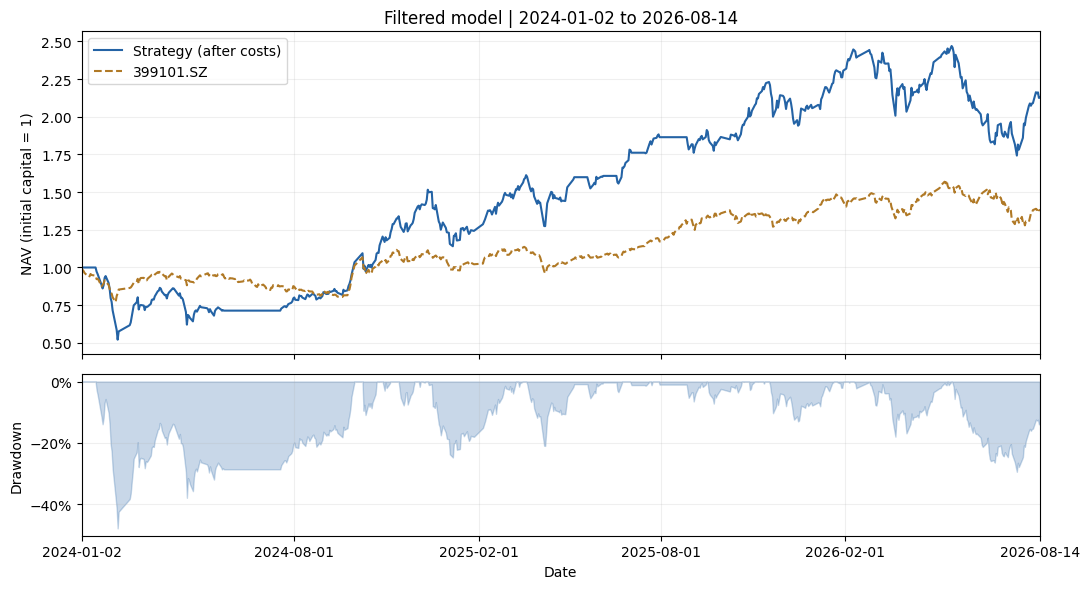

### 增强策略：模型 0%／动量 100%，宽度择时 ON

,累计收益,年化收益,最大回撤,Sharpe,训练窗口
0,75.87%,25.16%,17.27%,1.25,64


,year,strategy,benchmark,excess
0,2024,0.170924,0.038384,0.132540
1,2025,0.289967,0.316149,-0.026182
2,2026,0.164322,0.010203,0.154119


结果目录： C:\Users\1\Desktop\6400\qlib-LSTM-CNN strategy\CNN_LSTM_Project\outputs\filtered_enhanced_m075_no_breadth


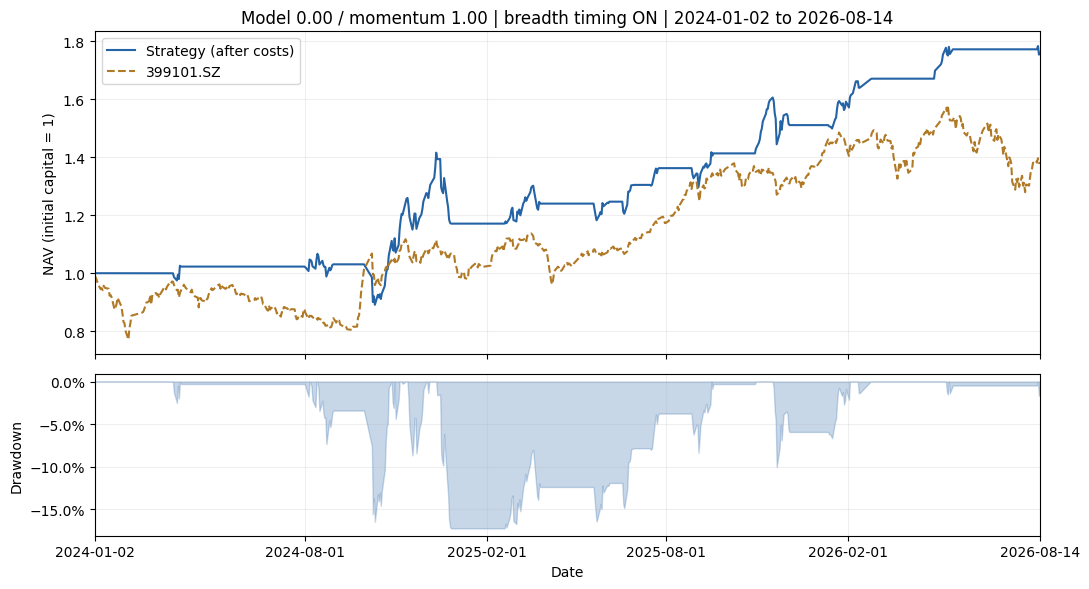

In [14]:
# Change CONFIG, then run this cell; no manual output-directory or training switch is needed.
try:
    CURRENT_RESULTS = refresh_results(CONFIG)
except RuntimeError as exc:
    # Missing compatible predictions is a visible pending state, not a fallback to old charts.
    if "没有与当前18项特征" not in str(exc):
        raise
    CURRENT_RESULTS = []
    display(Markdown(f"**18特征模型尚未训练，暂无新版收益图。**\n\n{exc}"))

for name, output in CURRENT_RESULTS:
    metrics = json.loads((output / "metrics.json").read_text(encoding="utf-8"))
    saved_config = json.loads((output / "config.json").read_text(encoding="utf-8"))
    title = "Filtered model" if saved_config.get("filters", {}).get("enabled") else "Model"
    label = "纯模型策略"
    if name == "enhanced":
        e = saved_config["enhanced"]
        timing = "ON" if e["breadth_timing"] else "OFF"
        title = f"Model {e['model_weight']:.2f} / momentum {e['momentum_weight']:.2f} | breadth timing {timing}"
        label = f"增强策略：模型 {e['model_weight']:.0%}／动量 {e['momentum_weight']:.0%}，宽度择时 {timing}"
    display(Markdown(f"### {label}"))
    display(pd.DataFrame([{"累计收益": f"{metrics['total_return']:.2%}",
        "年化收益": f"{metrics['annualized_return']:.2%}", "最大回撤": f"{metrics['max_drawdown']:.2%}",
        "Sharpe": round(metrics["sharpe"], 3), "训练窗口": metrics["successful_windows"]}]))
    display(pd.read_csv(output / "annual_returns.csv"))
    print("结果目录：", output.resolve())
    curves = pd.read_csv(output / "nav.csv", parse_dates=["datetime"])
    fig = plot_returns(curves, title)
    fig.savefig(output / "nav_drawdown.png", dpi=150)
    plt.show()
    plt.close(fig)
